# DDPM: generating four Gaussian clusters
### A small denoising diffusion probabilistic model

We use the same target as the flow-matching lesson: a two-dimensional Gaussian mixture with centers $(-2,-2)$, $(-2,2)$, $(2,-2)$, and $(2,2)$, equal weights, and standard deviation 0.35 in each coordinate.

This time we implement **DDPM**, with a fixed forward noising process, a network that predicts noise, and a stochastic reverse sampling chain. The sequence is **data → noise schedule → architecture → loss → training → reverse sampling → evaluation**.

**Notation changes:** $x_0$ is now clean data and $x_T$ is nearly standard Gaussian noise. Sampling runs backward from $T$ to 0. In the previous flow-matching lesson, time ran from noise at 0 to data at 1. Neither convention refers to physical time or a time-series index.

The notebook is self-contained and runs on the CPU. It needs no external data or images. Run from top to bottom with this folder as the working directory. Restart the kernel before repeating an experiment. All explanations are in Markdown; code cells contain no comments. `README.txt` gives setup and slide-rebuild instructions.

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(7)
torch.set_num_threads(1)
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 12})

## 1. Create the training data

Choose one of the four centers uniformly and add Gaussian noise:

$$X_0=\mu_C+0.35\varepsilon,\qquad
C\sim\mathrm{Uniform}\{1,2,3,4\},\quad\varepsilon\sim\mathcal N(0,I_2).$$

There are 4,096 training points, each with two coordinates. We know how to sample the target exactly; learning it is a controlled teaching experiment. The network receives noisy coordinates and a timestep, not the centers, component labels, or density formula.

In [2]:
centers = torch.tensor([[-2., -2.], [-2., 2.], [2., -2.], [2., 2.]])
sigma = 0.35

def sample_data(n):
    labels = torch.randint(4, (n,))
    return centers[labels] + sigma * torch.randn(n, 2)

x_train = sample_data(4096)

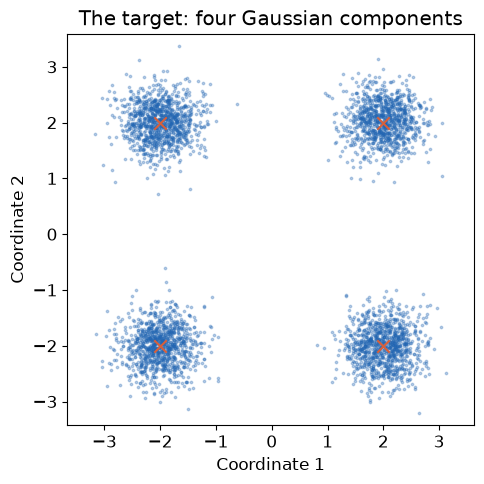

In [3]:
plt.figure(figsize=(5, 5))
plt.scatter(x_train[:, 0], x_train[:, 1], s=3, alpha=0.3, color="#2266B3")
plt.scatter(centers[:, 0], centers[:, 1], marker="x", s=80, color="#D6603C")
plt.xlabel("Coordinate 1")
plt.ylabel("Coordinate 2")
plt.title("The target: four Gaussian components")
plt.axis("equal")
plt.tight_layout()
plt.savefig("figures/training_data.pdf")
plt.show()

## 2. Define the forward noise schedule

For mathematical timesteps $t=1,\ldots,T$, the forward transition is

$$x_t=\sqrt{\alpha_t}\,x_{t-1}+\sqrt{\beta_t}\,\eta_t,
\qquad\eta_t\sim\mathcal N(0,I_2),\qquad\alpha_t=1-\beta_t.$$

The fresh noises $\eta_t$ are independent. Define $\bar\alpha_t=\prod_{s=1}^t\alpha_s$ and $\bar\alpha_0=1$. We use $T=1000$ and a linear schedule from $\beta_1=0.0001$ to $\beta_T=0.02$.

**Indexing:** Python index `k` refers to mathematical timestep $t=k+1$. Thus `alpha_bar[0]` is $\bar\alpha_1$, not $\bar\alpha_0$. The network receives normalized time $(k+1)/T$.

In [4]:
T = 1000
beta = torch.linspace(0.0001, 0.02, T)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)
print(f"Final alpha_bar: {alpha_bar[-1]:.8f}")

Final alpha_bar: 0.00004036


### A shortcut for sampling any noise level

Because the forward transitions are linear and Gaussian, we can directly draw

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\varepsilon,
\qquad\varepsilon\sim\mathcal N(0,I_2).$$

Here $\varepsilon$ is the **aggregate standardized noise** at timestep $t$, not the noise from just the last transition. This identity samples the correct conditional marginal $q(x_t\mid x_0)$. Independent shortcut draws at different times are not a forward Markov trajectory.

Our schedule gives $\bar\alpha_T\approx4.04\times10^{-5}$. The signal coefficient is only $\sqrt{\bar\alpha_T}\approx0.00635$, so the four-center target becomes very close to $\mathcal N(0,I_2)$ at $T$, though not exactly equal. A schedule that leaves too much signal would make standard Gaussian initialization inaccurate.

For the plot below, we explicitly simulate the forward Markov chain using fresh noise at each step. A separate random generator keeps this visualization from changing the training random stream. The panels follow the same 1,500 points.

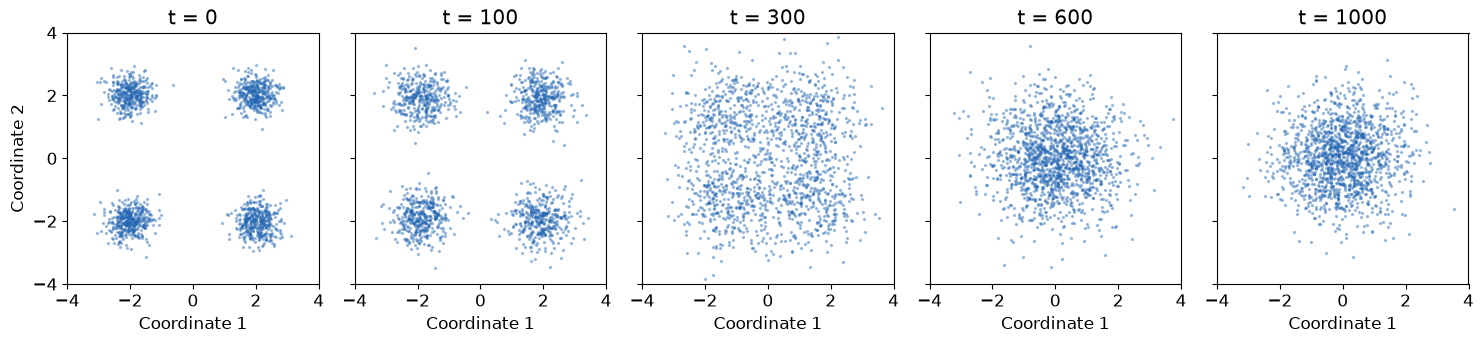

In [5]:
plot_rng = torch.Generator().manual_seed(123)
x = x_train[:1500].clone()
forward_path = [x.clone()]
for k in range(T):
    noise = torch.randn(x.shape, generator=plot_rng)
    x = alpha[k].sqrt() * x + beta[k].sqrt() * noise
    forward_path.append(x.clone())
forward_path = torch.stack(forward_path)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharex=True, sharey=True)
for ax, t in zip(axes, [0, 100, 300, 600, 1000]):
    points = forward_path[t]
    ax.scatter(points[:, 0], points[:, 1], s=2, alpha=0.35, color="#2266B3")
    ax.set(title=f"t = {t}", xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
    ax.set_xlabel("Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/forward_noising.pdf")
plt.show()

## 3. Define the noise-prediction network

The inputs are the noisy position $(x_t^{(1)},x_t^{(2)})$ and normalized time $t/T$. The output is a two-dimensional estimate $\varepsilon_\theta(x_t,t)$ of the aggregate noise.

We reuse the small architecture from the ODE lesson: two hidden layers of width 64, smooth `SiLU` activations, and **4,546 parameters**. The output now predicts noise, not velocity. The last layer has no activation, so its output can have either sign.

In [6]:
model = nn.Sequential(
    nn.Linear(3, 64),
    nn.SiLU(),
    nn.Linear(64, 64),
    nn.SiLU(),
    nn.Linear(64, 2)
)

## 4. Define the loss and optimizer

We minimize the simplified DDPM noise-prediction objective. For a batch of $B$ examples, PyTorch computes

$$L=\frac{1}{2B}\sum_{i=1}^{B}
\left\|\varepsilon_i-\varepsilon_\theta(x_{t_i},t_i)\right\|^2.$$

The factor $1/2$ is because `MSELoss` averages over both coordinates. We sample timesteps uniformly and do not apply additional timestep weights. This simplified objective is not the full variational likelihood bound.

The same noisy point can come from different clean points and noises. The optimal regression predictor is a conditional average $\mathbb E[\varepsilon\mid x_t,t]$, so zero loss is not generally possible. An always-zero noise predictor has expected MSE 1 per coordinate, which gives a useful reference, not a success threshold.

In [7]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 5. Train at randomly chosen noise levels

Each iteration samples 256 clean points with replacement, a separate timestep for every row, and fresh Gaussian noise. We construct $x_t$ directly with the shortcut. There is no need to run all 1,000 forward steps during training.

`a` has shape `(256, 1)` and broadcasts across two coordinates. Joining `xt` and `t` creates a `(256, 3)` network input. There are **10,000 parameter-update iterations**; this count is different from the **1,000 diffusion timesteps**.

In [8]:
history = []
for step in range(10000):
    x0 = x_train[torch.randint(len(x_train), (256,))]
    k = torch.randint(T, (256,))
    noise = torch.randn_like(x0)
    a = alpha_bar[k].reshape(-1, 1)
    xt = a.sqrt() * x0 + (1 - a).sqrt() * noise
    t = (k + 1).reshape(-1, 1) / T
    prediction = model(torch.cat([xt, t], dim=1))
    loss = loss_fn(prediction, noise)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    history.append(loss.item())

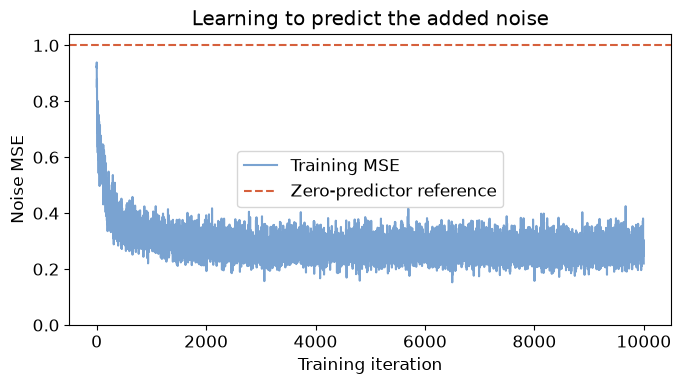

In [9]:
plt.plot(history, color="#2266B3", alpha=0.6, label="Training MSE")
plt.axhline(1, color="#D6603C", linestyle="--", label="Zero-predictor reference")
plt.xlabel("Training iteration")
plt.ylabel("Noise MSE")
plt.title("Learning to predict the added noise")
plt.legend()
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig("figures/loss_curve.pdf")
plt.show()

## 6. Construct the reverse sampler

Given $x_t$, the learned reverse mean is

$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\varepsilon_\theta(x_t,t)\right).$$

We choose a fixed reverse variance

$$\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t},\qquad\bar\alpha_0=1.$$

This is the variance of the forward posterior conditioned on both $x_t$ and the clean $x_0$. Using it as a fixed variance for the learned Gaussian reverse transition is a standard DDPM choice; it does not make the learned transition the exact reverse conditional for a mixture.

For $t>1$, draw fresh $z_t\sim\mathcal N(0,I_2)$ and set

$$x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\tilde\beta_t}\,z_t.$$

At the last step, $t=1$, we return the mean without adding noise. Here $\tilde\beta_1=0$. We do not clip coordinates to $[-1,1]$: our data are real-valued points with centers outside that interval.

In [10]:
alpha_bar_previous = torch.cat([torch.ones(1), alpha_bar[:-1]])
reverse_variance = beta * (1 - alpha_bar_previous) / (1 - alpha_bar)

The sampler starts from standard Gaussian noise and visits every timestep in reverse order. Its `path` is indexed by **completed reverse steps**: `path[0]` is $x_T$ and `path[T]` is the generated $x_0$.

The default `stochastic=True` implements our DDPM sampler. The optional `False` setting is only an experiment that removes the reverse-step noise. It is **not** a DDIM or probability-flow ODE sampler.

With the same initial point, different reverse noise draws can lead to different outputs. Reproducing a DDPM sample requires reproducing the whole random stream, not only its initial Gaussian point.

In [11]:
def generate(z, stochastic=True):
    x = z.clone()
    path = [x.clone()]
    with torch.no_grad():
        for k in reversed(range(T)):
            t = torch.full((len(x), 1), (k + 1) / T)
            predicted_noise = model(torch.cat([x, t], dim=1))
            x = (x - beta[k] * predicted_noise / (1 - alpha_bar[k]).sqrt()) / alpha[k].sqrt()
            if k > 0 and stochastic:
                x = x + reverse_variance[k].sqrt() * torch.randn_like(x)
            path.append(x.clone())
    return x, torch.stack(path)

## 7. Generate and evaluate new samples

Training is complete. We use evaluation seed 2026 to draw 5,000 new Gaussian starting points and 5,000 new real samples. The real samples are used only for evaluation. The sampler uses the trained model and schedule, not target centers, labels, or real test values.

These are newly generated points, not reconstructions of paired training points. A generated point has no individually prescribed correct endpoint.

In [12]:
torch.manual_seed(2026)
model.eval()
z = torch.randn(5000, 2)
real_test = sample_data(5000)
generated, path = generate(z)
print("Five new DDPM samples:")
print(generated[:5])

Five new DDPM samples:
tensor([[ 2.1844,  2.2004],
        [-1.6434, -1.9056],
        [ 1.8349,  1.8495],
        [ 2.0955,  2.4595],
        [-2.0331, -2.0692]])


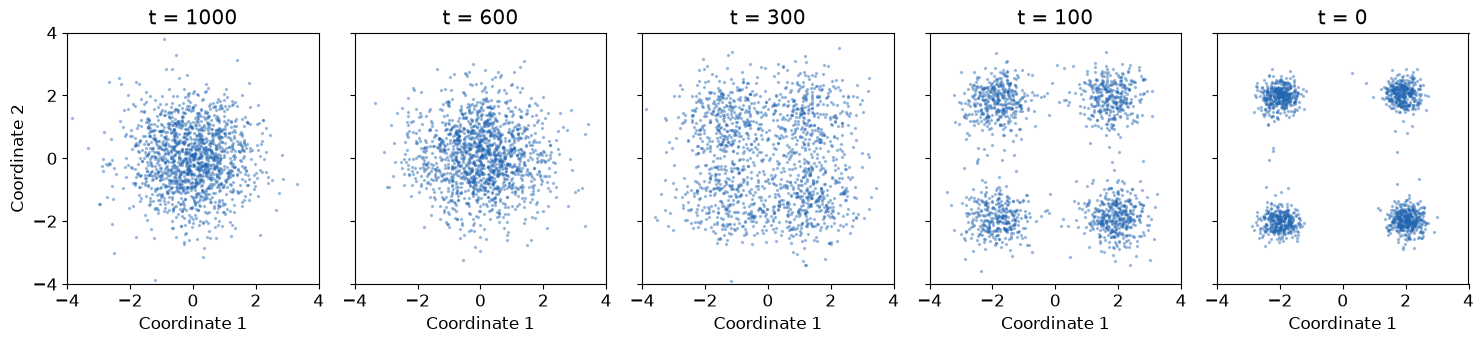

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharex=True, sharey=True)
for ax, t in zip(axes, [1000, 600, 300, 100, 0]):
    points = path[T - t, :1500]
    ax.scatter(points[:, 0], points[:, 1], s=2, alpha=0.35, color="#2266B3")
    ax.set(title=f"t = {t}", xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
    ax.set_xlabel("Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/reverse_sampling.pdf")
plt.show()

The next plot follows eight actual reverse trajectories. They are irregular because reverse transitions add fresh Gaussian noise. Open circles mark starts; filled dots mark generated endpoints. Colors indicate the nearest final center. These are sampling trajectories, not time series from the target data.

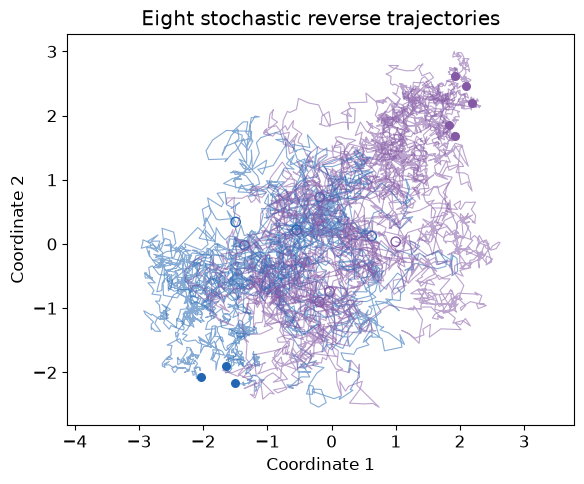

In [14]:
colors = ["#2266B3", "#D6603C", "#008878", "#8459A5"]
groups = torch.cdist(generated[:8], centers).argmin(dim=1)
plt.figure(figsize=(6, 5))
for j in range(8):
    points = path[:, j]
    color = colors[groups[j].item()]
    plt.plot(points[:, 0], points[:, 1], color=color, alpha=0.55, linewidth=0.8)
    plt.scatter(*points[0], facecolors="none", edgecolors=color, s=45)
    plt.scatter(*points[-1], color=color, s=30)
plt.xlabel("Coordinate 1")
plt.ylabel("Coordinate 2")
plt.title("Eight stochastic reverse trajectories")
plt.axis("equal")
plt.tight_layout()
plt.savefig("figures/trajectories.pdf")
plt.show()

We compare the first 2,000 fresh real and generated points on equal axes. The red crosses are the target centers. Seeing four clusters is a useful first check, but does not establish the correct weights, widths, or tails.

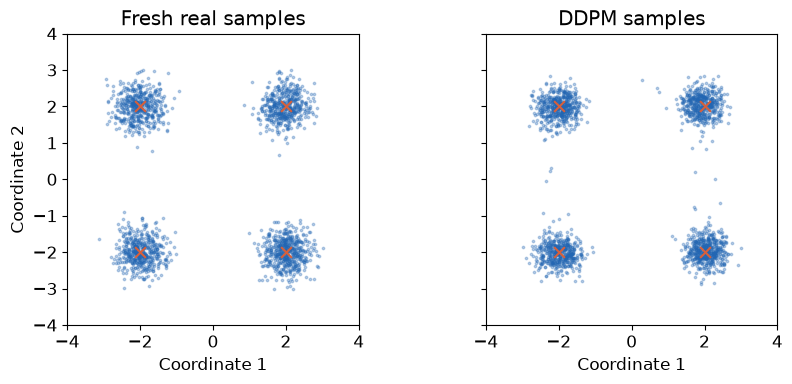

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, points, title in zip(axes, [real_test, generated], ["Fresh real samples", "DDPM samples"]):
    ax.scatter(points[:2000, 0], points[:2000, 1], s=3, alpha=0.3, color="#2266B3")
    ax.scatter(centers[:, 0], centers[:, 1], marker="x", s=60, color="#D6603C")
    ax.set(title=title, xlim=(-4, 4), ylim=(-4, 4), aspect="equal", xlabel="Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/sample_comparison.pdf")
plt.show()

### Distribution diagnostics

As in the ODE lesson, assign points to their nearest center and compare the four proportions, root mean squared radius, and percentage within distance 1 of a center. The mixture weights are 25% each, but finite-sample counts vary. Nearest-center assignments are diagnostics, not known latent labels.

Compare spread to the fresh real samples. Very small radius is not automatically better: a generator that collapses each cluster to its center would have radius zero. The radius-1 threshold is a descriptive choice, not a confidence interval. None of these checks alone proves a distribution match.

In [16]:
def summary(points):
    distance, group = torch.cdist(points, centers).min(dim=1)
    shares = 100 * torch.bincount(group, minlength=4) / len(points)
    radius = distance.square().mean().sqrt().reshape(1)
    nearby = 100 * (distance < 1).float().mean().reshape(1)
    return torch.cat([shares, radius, nearby])

print("Sample          C1%      C2%      C3%      C4%      RMSr    Near1%")
for name, points in [("Real test", real_test), ("DDPM", generated)]:
    print(f"{name:10s}" + "".join(f"{value:9.4f}" for value in summary(points)))

Sample          C1%      C2%      C3%      C4%      RMSr    Near1%
Real test   24.9000  24.3800  25.8600  24.8600   0.4934  98.4400
DDPM        24.7600  26.6800  24.1000  24.4600   0.4246  99.1400


## 8. Experiment: remove the reverse-step randomness

Use the same network, schedule, and Gaussian starting points, but take only the predicted mean at every step. The result may have much less variation within clusters. This demonstrates that noise in reverse transitions is part of the sampling model, not an accidental disturbance to discard.

This ablation changes the sampler. It is not a shortcut implementation of DDIM, an ODE, or a theoretically equivalent sampling method. No retraining or checkpoint selection occurs here.

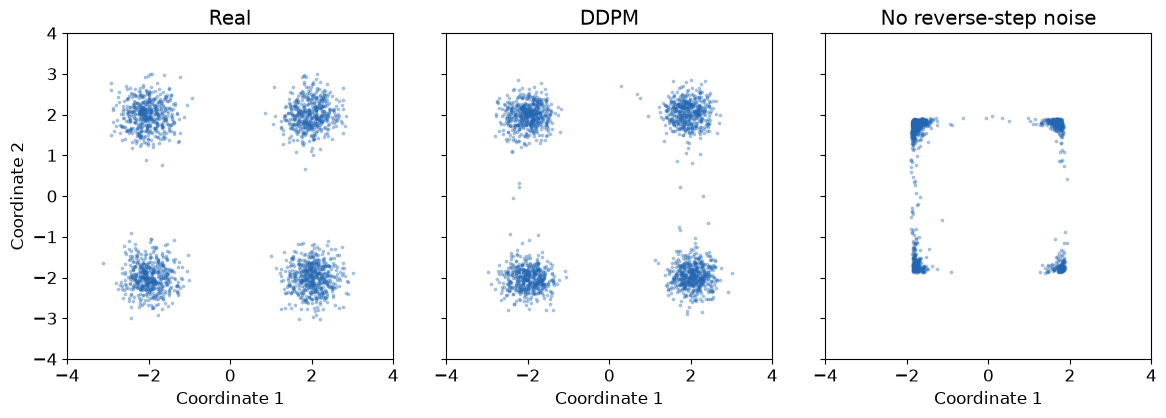

Mean-only RMS radius: 0.4292


In [17]:
mean_only, _ = generate(z, stochastic=False)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, points, title in zip(axes, [real_test, generated, mean_only],
                             ["Real", "DDPM", "No reverse-step noise"]):
    ax.scatter(points[:2000, 0], points[:2000, 1], s=3, alpha=0.3, color="#2266B3")
    ax.set(title=title, xlim=(-4, 4), ylim=(-4, 4), aspect="equal", xlabel="Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/noise_ablation.pdf")
plt.show()
print(f"Mean-only RMS radius: {summary(mean_only)[4]:.4f}")

### Reading the supplied run

The saved DDPM run puts roughly 24–27% of samples in each cluster. Its RMS distance to the nearest target center is **0.4246**, compared with **0.4934** for fresh real samples: it captures all four modes, but its clouds are somewhat tighter.

The mean-only chain visibly moves clusters inward and changes their shapes. Yet its RMS radius is **0.4292**, close to DDPM's. This is a useful warning about interpretation: distance from a target center mixes location error and spread, and a similar scalar value can hide very different distributions. Read the plots alongside the diagnostics. These numbers describe the supplied run; rerunning after changes can give different results.

## What changed from flow matching?

| | Flow-matching lesson | This DDPM lesson |
|---|---|---|
| Training state | Straight interpolation of noise and data | A noisy data point from a fixed Gaussian schedule |
| Network predicts | Velocity | Aggregate added noise |
| Loss | Velocity MSE | Noise MSE |
| Sampling | Euler steps in a learned ODE | Gaussian reverse transitions with a learned mean |
| Randomness | Initial Gaussian sample | Initial sample and reverse transitions except the last |
| Time convention | Noise at 0, data at 1 | Data at 0, noise at $T$ |

Both methods compare generated distributions to fresh real samples. We have not run a controlled benchmark: these teaching runs have different training and sampling budgets. Neither method is declared better from these plots.

The learned DDPM is approximate. Finite data, imperfect noise prediction, the approximate terminal Gaussian prior, and the chosen Gaussian reverse transitions all matter. It generates points in $\mathbb R^2$, not a time series; Volterra-signature modeling remains future work.

## Student experiments

1. Change the training seed and examine all four weights and cluster widths.
2. Use 2,000 parameter-update iterations. Does the loss alone reveal the quality of the generated distribution?
3. Use narrower target components by reducing `sigma`, then rerun both training and evaluation.
4. Reduce `T` to 100 while keeping the same beta endpoints. First inspect `alpha_bar[-1]`: is the terminal distribution still close enough to standard Gaussian? Update forward and reverse plot timesteps too. This changes the forward process and requires retraining.
5. Repeat sampling with the same initial `z` but a different random seed. Do the endpoints stay the same?

Do not speed up this DDPM sampler by simply skipping indices with the original one-step coefficients; a correctly derived accelerated sampler needs different transitions. If evaluation results guide tuning, reserve fresh data for a final test.

**References**

- Ho, Jain, and Abbeel (2020), [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239), especially Algorithms 1–2 and the fixed reverse-variance choices in Section 3.2.
- [Authors' implementation](https://github.com/hojonathanho/diffusion), for the original DDPM algorithms.
- Song, Meng, and Ermon, [Denoising Diffusion Implicit Models](https://arxiv.org/abs/2010.02502), for a distinct family of sampling updates; our mean-only ablation is not DDIM.